# M1 requirement 5: Exploring the tutoring paradox

**Decision:** Should the district cut tutoring funding because participants fail more often?

We describe the headline comparison and repeat it inside prior-year GPA groups, a measure recorded before this school year. The unit is a student. “Attended” means at least one recorded Present session during the year; the comparison is students with no recorded attendance. Referral alone is not attendance. The outcome is at least one failing course-term during the year (F in term 1; below 60 in terms 2–3).

This descriptive analysis cannot establish tutoring's effect. Referrals target students of concern, participation is voluntary, and full-year attendance can occur after an earlier failure. A separate term-3 comparison uses only attendance before term 3.

Run `python clean_data.py` first, then run all cells from this folder. Full CSVs are used; sample files overlap them and must not be appended.

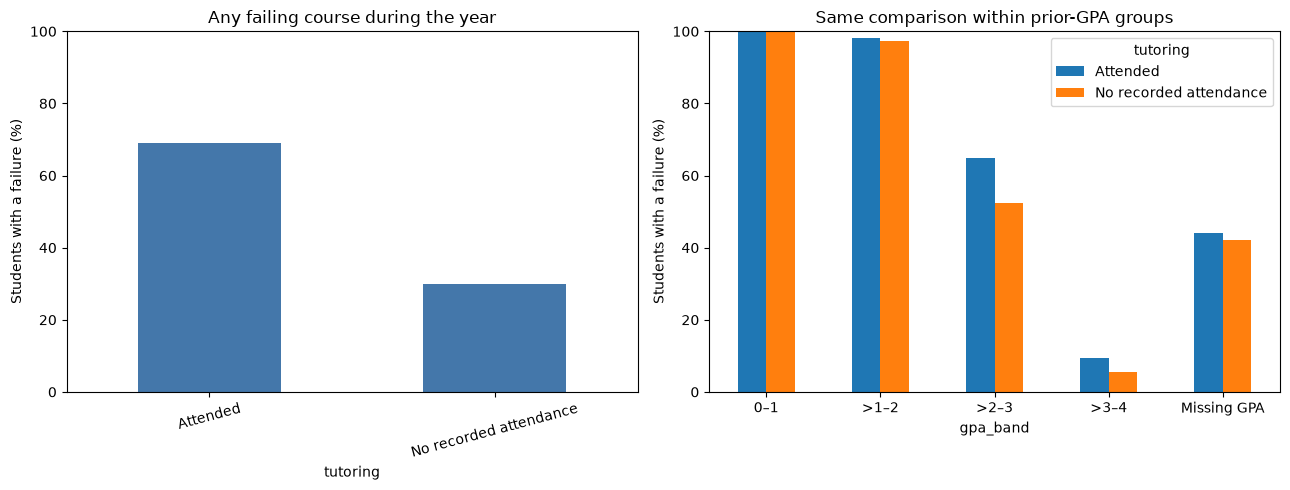

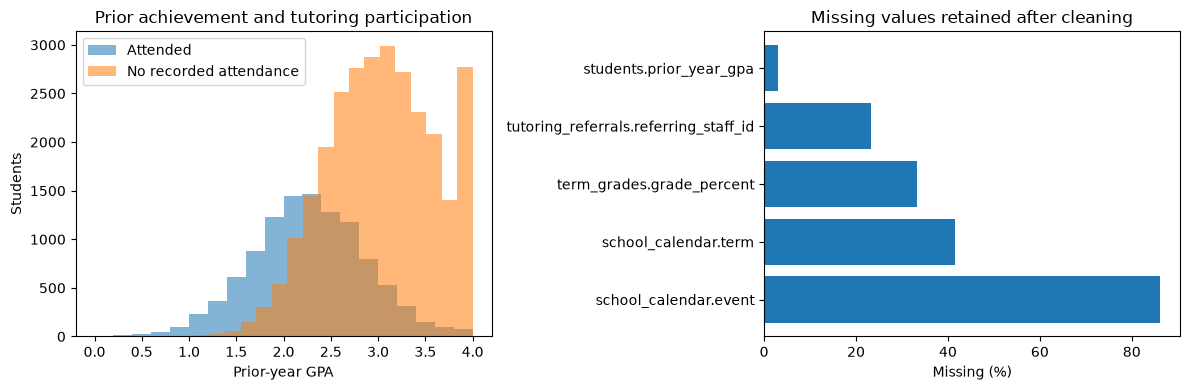

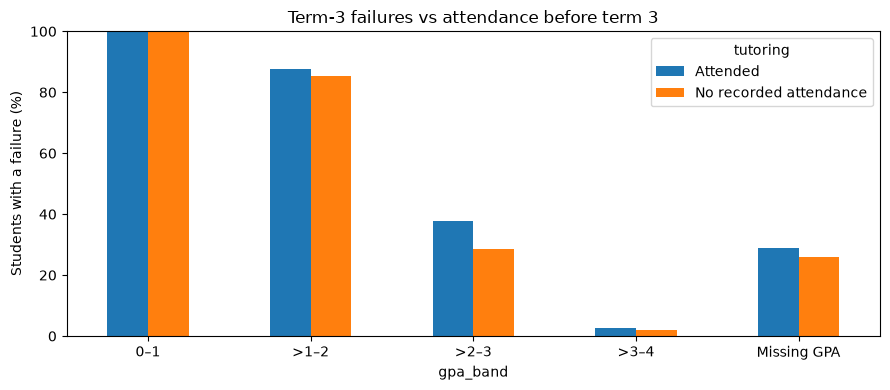

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / '.python_packages'))
from IPython.display import display
from exploration import run, rates
tables, students, summaries = run()

## Summary statistics and data quality
Numeric summaries exclude missing values. Term-1 letters have no numeric percentage and are excluded from percentage summaries. Missing GPA is retained as its own comparison group; no outcomes or GPA values are imputed.

In [2]:
for name in ['student_summary', 'grade_summary', 'attendance_counts']:
    print(name)
    display(summaries[name])
import pandas as pd
audit = pd.read_csv('cleaned/cleaning_audit.csv')
display(audit[['file','step','rows_before','rows_after','affected_values','reason']])
missing = pd.read_csv('cleaned/missingness.csv')
display(missing[missing.missing.gt(0)])

student_summary


,prior_year_gpa,grade_level
count,38797.000000,40000.000000
mean,2.818090,10.397100
std,0.670291,1.113909
min,0.000000,9.000000
25%,2.370000,9.000000
50%,2.830000,10.000000
75%,3.300000,11.000000
max,4.000000,12.000000


grade_summary


,grade_percent,absences
count,480000.000000,720000.000000
mean,78.088740,3.913307
std,13.882676,3.442440
min,6.000000,0.000000
25%,69.000000,2.000000
50%,79.000000,3.000000
75%,89.000000,5.000000
max,100.000000,40.000000


attendance_counts


,sessions
attendance,
Present,234820
Absent,178550


,file,step,rows_before,rows_after,affected_values,reason
0,schools,load,24,24,0,Loaded schools.csv; sample exports are overlap...
1,schools,text and missing markers,24,24,0,"Trim whitespace, collapse repeated spaces, sta..."
2,schools,categories,24,24,0,Normalize category case; unrecognized labels b...
3,schools,types and ranges,24,24,0,Parse ISO dates and numeric fields; invalid or...
4,schools,validate school_code,24,24,0,Malformed identifier becomes missing; preserve...
...,...,...,...,...,...,...
99,sections,save / missing policy,9651,9651,0,Keep missing optional values; exclude unknown ...
100,term_grades,save / missing policy,720000,720000,0,Keep missing optional values; exclude unknown ...
101,tutors,save / missing policy,614,614,0,Keep missing optional values; exclude unknown ...
102,tutoring_referrals,save / missing policy,14917,14917,0,Keep missing optional values; exclude unknown ...


,file,column,rows,missing
10,school_calendar,event,304,262
11,school_calendar,term,304,126
22,students,prior_year_gpa,40000,1203
41,term_grades,grade_percent,720000,240000
54,tutoring_referrals,referring_staff_id,14917,3464


## Headline comparison and comparison within groups
Each table reports students, known outcomes, failures, unknown outcomes, and failure percentages among known outcomes. An observed F establishes failure; if a student has no observed F and fewer than all expected grades, the outcome stays unknown. Students with unknown attendance and no known Present session form their own exposure category.

In [3]:
display(summaries['overall_failure_rates'])
display(summaries['failure_rates_by_prior_gpa'])
display(summaries['failure_rates_by_bus_rider'])

,students,known_outcomes,failures,unknown_outcomes,failure_pct
tutoring,,,,,
Attended,11240,11240,7763,0,69.065836
No recorded attendance,28760,28760,8617,0,29.961752


students  known_outcomes  failures  \
gpa_band    tutoring                                                     
0–1         Attended                     201             201       201   
            No recorded attendance         3               3         3   
>1–2        Attended                    3368            3368      3306   
            No recorded attendance       967             967       940   
>2–3        Attended                    6149            6149      3985   
            No recorded attendance     12465           12465      6526   
>3–4        Attended                    1151            1151       107   
            No recorded attendance     14493           14493       797   
Missing GPA Attended                     371             371       164   
            No recorded attendance       832             832       351   

                                    unknown_outcomes  failure_pct  
gpa_band    tutoring                                               
0–1         Attended                               0        100.0  
            No recorded attendance                 0        100.0  
>1–2        Attended                               0    98.159145  
            No recorded attendance                 0    97.207859  
>2–3        Attended                               0    64.807286  
            No recorded attendance                 0    52.354593  
>3–4        Attended                               0     9.296264  
            No recorded attendance                 0     5.499207  
Missing GPA Attended                               0    44.204852  
            No recorded attendance                 0      42.1875

students  known_outcomes  failures  \
bus_rider tutoring                                                     
N         Attended                    4447            4447      3007   
          No recorded attendance     12128           12128      3498   
Y         Attended                    6793            6793      4756   
          No recorded attendance     16632           16632      5119   

                                  unknown_outcomes  failure_pct  
bus_rider tutoring                                               
N         Attended                               0    67.618619  
          No recorded attendance                 0    28.842348  
Y         Attended                               0    70.013249  
          No recorded attendance                 0    30.778018

## Patterns in the observed data

In [4]:
overall = summaries['overall_failure_rates']
if {'Attended', 'No recorded attendance'}.issubset(overall.index):
    gap = overall.loc['Attended','failure_pct'] - overall.loc['No recorded attendance','failure_pct']
    print(f'Overall attendance-minus-no-attendance failure gap: {gap:.2f} percentage points.')
    display(students.groupby('tutoring').prior_year_gpa.agg(['count','mean','median']))
    grouped = summaries['failure_rates_by_prior_gpa'].failure_pct.unstack('tutoring')
    grouped['gap_percentage_points'] = grouped['Attended'] - grouped['No recorded attendance']
    display(grouped)
    print('Positive gaps mean higher observed failure among attendees; negative gaps mean lower failure.')

Overall attendance-minus-no-attendance failure gap: 39.10 percentage points.


,count,mean,median
tutoring,,,
Attended,10869,2.267864,2.26
No recorded attendance,27928,3.032227,3.03


tutoring,Attended,No recorded attendance,gap_percentage_points
gpa_band,,,
0–1,100.0,100.0,0.0
>1–2,98.159145,97.207859,0.951286
>2–3,64.807286,52.354593,12.452693
>3–4,9.296264,5.499207,3.797058
Missing GPA,44.204852,42.1875,2.017352


Positive gaps mean higher observed failure among attendees; negative gaps mean lower failure.


## Timing sensitivity
The outcome below is any term-3 failure. Exposure is any attendance before 2026-02-18, the first day of term 3. Students who only attend later belong to the no-prior-attendance comparison. This avoids using later attendance to explain earlier outcomes, but referral selection and other confounding remain.

In [5]:
display(summaries['term3_failure_by_preterm_attendance'])

students  known_outcomes  failures  \
gpa_band    tutoring                                                     
0–1         Attended                     194             194       194   
            No recorded attendance        10              10        10   
>1–2        Attended                    3199            3199      2806   
            No recorded attendance      1136            1136       970   
>2–3        Attended                    5655            5655      2143   
            No recorded attendance     12959           12959      3699   
>3–4        Attended                    1033            1033        27   
            No recorded attendance     14611           14611       269   
Missing GPA Attended                     335             335        97   
            No recorded attendance       868             868       225   

                                    unknown_outcomes  failure_pct  
gpa_band    tutoring                                               
0–1         Attended                               0        100.0  
            No recorded attendance                 0        100.0  
>1–2        Attended                               0    87.714911  
            No recorded attendance                 0    85.387324  
>2–3        Attended                               0    37.895668  
            No recorded attendance                 0    28.543869  
>3–4        Attended                               0     2.613746  
            No recorded attendance                 0     1.841079  
Missing GPA Attended                               0    28.955224  
            No recorded attendance                 0    25.921659

## Interpretation and limits

In the supplied exports, 69.07% of attendees and 29.96% of students with no recorded attendance had at least one failing course-term, a 39.10 percentage-point gap. After grouping by prior GPA, the gap is 0.95 points for GPA >1–2, 12.45 points for >2–3, and 3.80 points for >3–4. The lowest band has 100% failure in both groups and only three nonattendees. Thus the headline gap shrinks substantially within bands but does not reverse. These results do not establish that tutoring causes harm or that it helps; baseline selection explains part of the observed difference, with other differences unresolved.

Compare the overall gap with the gap in each GPA group. A reversal would support a selection explanation for the headline; mixed or unchanged gaps should be reported as such. Prior GPA distributions show whether attendees started with different achievement. GPA bands are coarse and do not eliminate differences within groups. Missing GPA may reflect unavailable transfer transcripts and should not be treated as average achievement.

Bus-rider groups explore the district's lack of late buses, but bus assignment does not directly measure transport availability. Repeated course grades are collapsed to student outcomes so a student is counted once per comparison. No significance or causal claim is justified by these descriptive comparisons alone. Quarantined records and unknown outcomes may affect the comparison; inspect the audit and missingness tables before drawing conclusions.

The export excludes students who left the district and does not record referral reasons or private tutoring. Retain funding decisions pending a design that accounts for baseline achievement, referral timing, subject and attendance barriers. Figures and summary tables are saved in `analysis_outputs/`.